# Zomato Data analysis

In [59]:
import pandas as pd
import numpy as np 
import matplotlib as plt
import seaborn as sns

In [60]:
df= pd.read_csv("Zomato data .csv")

In [61]:
df

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet
...,...,...,...,...,...,...,...
143,Melting Melodies,No,No,3.3/5,0,100,Dining
144,New Indraprasta,No,No,3.3/5,0,150,Dining
145,Anna Kuteera,Yes,No,4.0/5,771,450,Dining
146,Darbar,No,No,3.0/5,98,800,Dining


In [62]:
def func(values):
    values=str(values).split("/")
    values=values[0]
    return float(values)
   
df['rate']=df['rate'].apply(func)


In [63]:
df

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet
...,...,...,...,...,...,...,...
143,Melting Melodies,No,No,3.3,0,100,Dining
144,New Indraprasta,No,No,3.3,0,150,Dining
145,Anna Kuteera,Yes,No,4.0,771,450,Dining
146,Darbar,No,No,3.0,98,800,Dining


In [64]:
df.head()

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


In [66]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   name                         148 non-null    str    
 1   online_order                 148 non-null    str    
 2   book_table                   148 non-null    str    
 3   rate                         148 non-null    float64
 4   votes                        148 non-null    int64  
 5   approx_cost(for two people)  148 non-null    int64  
 6   listed_in(type)              148 non-null    str    
dtypes: float64(1), int64(2), str(4)
memory usage: 8.2 KB


In [67]:
df.describe()

,rate,votes,approx_cost(for two people)
count,148.000000,148.000000,148.000000
mean,3.633108,264.810811,418.243243
std,0.402271,653.676951,223.085098
min,2.600000,0.000000,100.000000
25%,3.300000,6.750000,200.000000
50%,3.700000,43.500000,400.000000
75%,3.900000,221.750000,600.000000
max,4.600000,4884.000000,950.000000


In [68]:
df2=df.head(10)

In [69]:
df2

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet
5,Timepass Dinner,Yes,No,3.8,286,600,Buffet
6,Rosewood International Hotel - Bar & Restaurant,No,No,3.6,8,800,Buffet
7,Onesta,Yes,Yes,4.6,2556,600,Cafes
8,Penthouse Cafe,Yes,No,4.0,324,700,other
9,Smacznego,Yes,No,4.2,504,550,Cafes


In [70]:
df.shape

(148, 7)

<Axes: xlabel='approx_cost(for two people)', ylabel='book_table'>

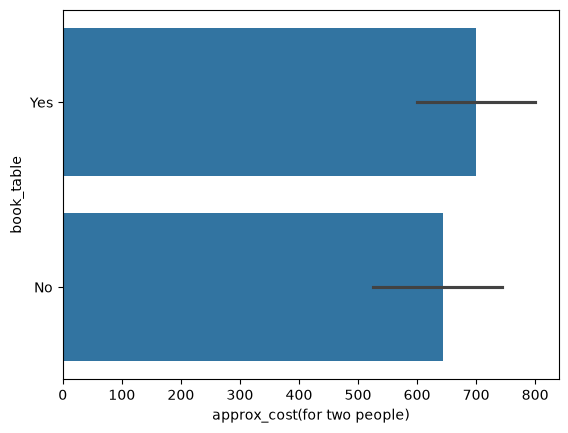

In [71]:
sns.barplot(data=df2,x="approx_cost(for two people)", y="book_table")

<Axes: xlabel='rate', ylabel='Density'>

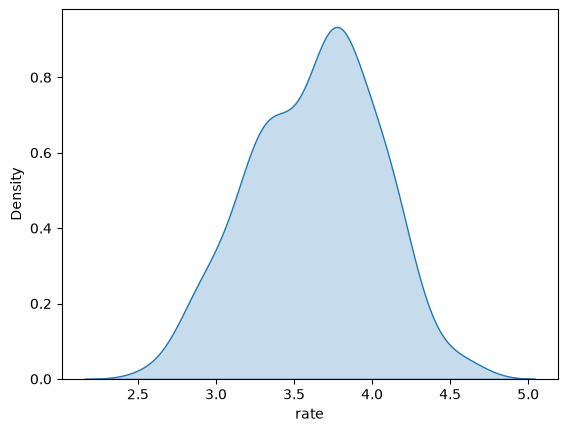

In [72]:
sns.kdeplot(data=df,x="rate",fill=True)

<Axes: xlabel='listed_in(type)', ylabel='count'>

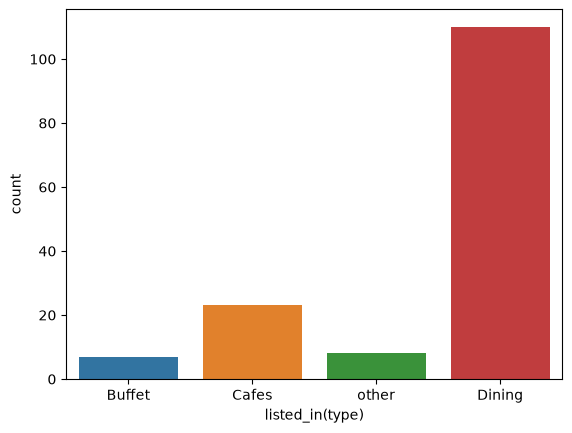

In [74]:
sns.countplot(data=df,x="listed_in(type)",hue='listed_in(type)')

<Axes: xlabel='rate', ylabel='votes'>

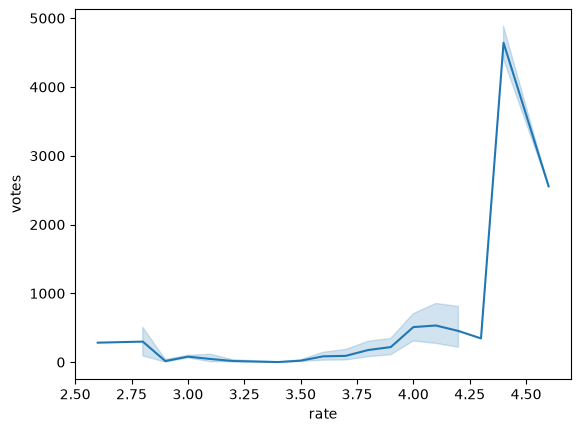

In [75]:
sns.lineplot(data=df,x="rate",y="votes")

<Axes: xlabel='online_order', ylabel='approx_cost(for two people)'>

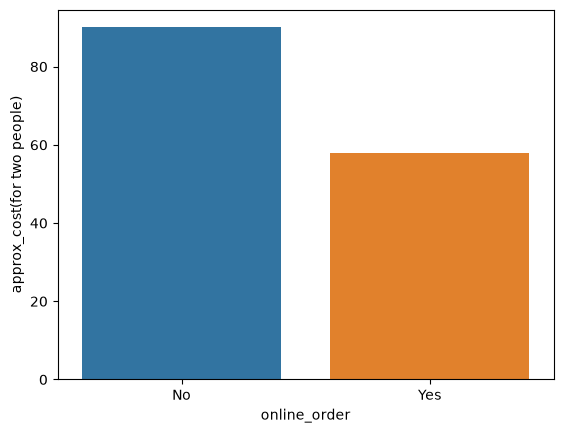

In [76]:

df3=df.groupby(['online_order'],as_index=False)['approx_cost(for two people)'].count()
sns.barplot(data=df3,x='online_order',y='approx_cost(for two people)',hue='online_order')


In [77]:
x1=df.groupby('name')['approx_cost(for two people)'].sum().sort_values(ascending=False)

In [78]:
x1

name
San Churro Cafe         1600
Onesta                  1200
CAFE NOVA               1200
Ayda Persian Kitchen     950
Cafe Coffee Day          900
                        ... 
Chill Out                100
Coffee Bytes             100
Ruchi Maayaka            100
Namma Brahmin's Idli     100
Melting Melodies         100
Name: approx_cost(for two people), Length: 145, dtype: int64

<Axes: xlabel='approx_cost(for two people)', ylabel='count'>

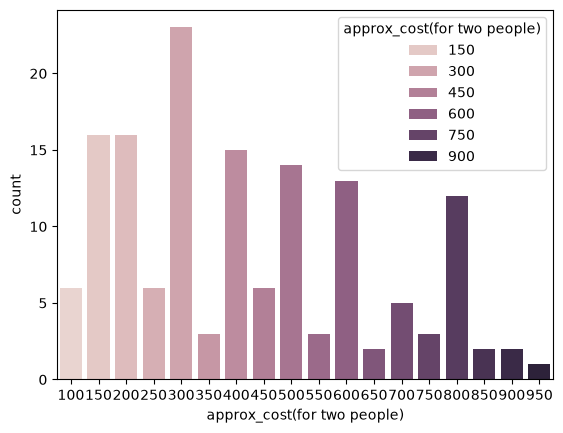

In [79]:
sns.countplot(data=df,x='approx_cost(for two people)',hue='approx_cost(for two people)')

<Axes: xlabel='online_order', ylabel='rate'>

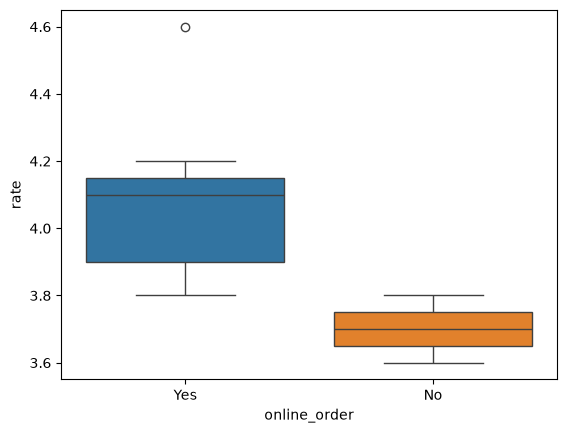

In [80]:
sns.boxplot(data=df2,x="online_order", y="rate",hue='online_order')

<Axes: xlabel='votes', ylabel='listed_in(type)'>

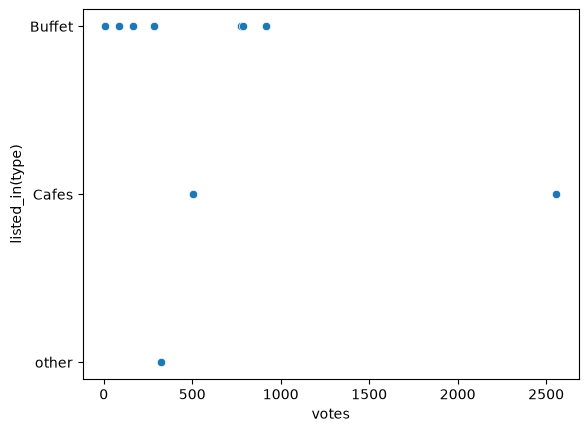

In [82]:
sns.scatterplot(data=df2,x='votes',y='listed_in(type)',)

In [83]:
a1=df.head(10)

In [84]:
a1.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   name                         10 non-null     str    
 1   online_order                 10 non-null     str    
 2   book_table                   10 non-null     str    
 3   rate                         10 non-null     float64
 4   votes                        10 non-null     int64  
 5   approx_cost(for two people)  10 non-null     int64  
 6   listed_in(type)              10 non-null     str    
dtypes: float64(1), int64(2), str(4)
memory usage: 692.0 bytes


In [85]:
a1

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet
5,Timepass Dinner,Yes,No,3.8,286,600,Buffet
6,Rosewood International Hotel - Bar & Restaurant,No,No,3.6,8,800,Buffet
7,Onesta,Yes,Yes,4.6,2556,600,Cafes
8,Penthouse Cafe,Yes,No,4.0,324,700,other
9,Smacznego,Yes,No,4.2,504,550,Cafes


<Axes: xlabel='online_order', ylabel='count'>

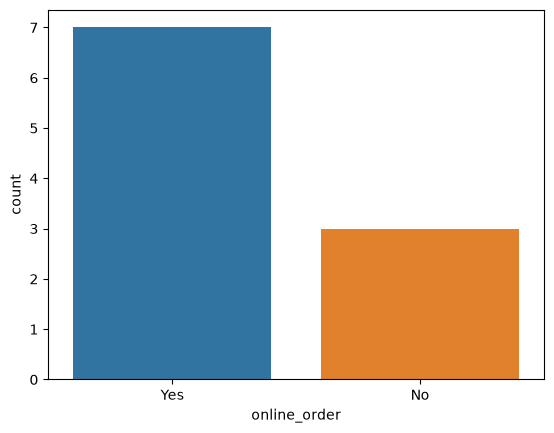

In [88]:
sns.countplot(data=a1,x="online_order",hue='online_order')

<Axes: xlabel='online_order', ylabel='rate'>

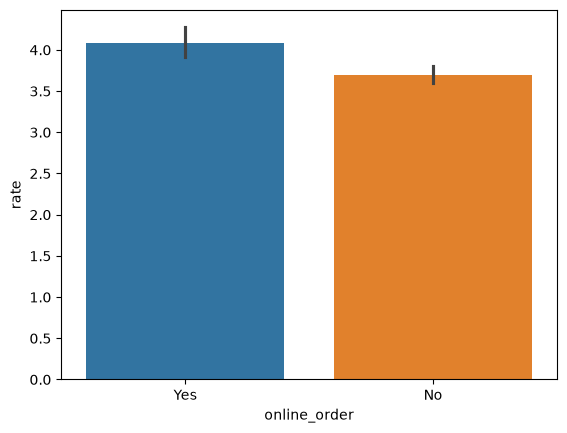

In [90]:
sns.barplot(data=a1,x="online_order" , y="rate",hue='online_order')

In [102]:
print(f"total of votes {df2['votes'].sum()}")

total of votes 6412


In [106]:
d1 =  df.groupby(by= "listed_in(type)").sum(numeric_only=True)

In [107]:
d1

,rate,votes,approx_cost(for two people)
listed_in(type),,,
Buffet,26.9,3028,4700
Cafes,86.6,6434,12550
Dining,392.9,20363,39300
other,31.3,9367,5350


<Axes: xlabel='listed_in(type)', ylabel='votes'>

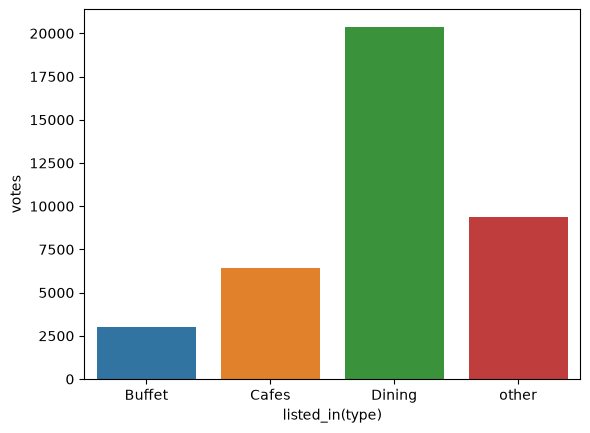

In [111]:
sns.barplot(data = d1 , x="listed_in(type)" , y="votes" , hue="listed_in(type)") 